# Instagram Reach & Engagement Analytics
**Research question:** How do exposure and engagement metrics relate to profile visits and follows in this small dataset?

Dataset provenance and collection dates are not independently verified. No causal inferences.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT / 'src'))
import analyze
import pandas as pd
import matplotlib.pyplot as plt
print('Project root:', ROOT)

Project root: /Users/fatmacakir/Downloads/Instagram_Reach_Project


## 1. Load, inspect and clean
Exact duplicates are removed for the primary analysis; the raw source is preserved.

In [2]:
raw, posts, quality = analyze.load_prepare()
print('Raw:',raw.shape,'Cleaned:',posts.shape)
pd.Series(quality)

Raw: (119, 13) Cleaned: (102, 30)


raw_rows                                        119
exact_duplicate_rows                             17
analysis_rows                                   102
missing_numeric_cells                             0
traffic_mismatch_rows                           102
traffic_sum_exceeds_impressions_rows              4
follows_greater_than_profile_visits_rows          4
no_post_ids                                    True
no_dates_or_content_format                     True
provenance_and_publication_dates_unverified    True
dtype: object

In [3]:
display(posts[['post_key','impressions','likes','comments','shares','saves','profile_visits','follows','engagement_per_impression_pct']].head())
print('Missing cells:',posts.isna().sum().sum())

,post_key,impressions,likes,comments,shares,saves,profile_visits,follows,engagement_per_impression_pct
0,post_001,3920,162,9,5,98,35,2,6.989796
1,post_002,5394,224,7,14,194,48,10,8.138673
2,post_003,4021,131,11,1,41,62,12,4.575976
3,post_004,4528,213,10,7,172,23,8,8.878092
4,post_005,2518,123,5,4,96,8,0,9.054805


Missing cells: 0


## 2. Calculate KPIs and export Tableau data
Weighted rates use sum(numerator) divided by sum(impressions), not the mean of individual post rates.

In [4]:
results, traffic, quartiles = analyze.make_results(posts)
display(pd.DataFrame([results['kpis']]).T.rename(columns={0:'value'}))

,value
posts_analyzed,102.000
total_impressions,603866.000
total_interactions,35601.000
total_profile_visits,5576.000
total_follows,2328.000
engagement_per_impression_pct,5.896
profile_visit_rate_pct,0.923
follows_per_impression_pct,0.386
follows_per_visit_proxy_pct,41.750


## 3. Explore reach, engagement, and traffic
Traffic source counts are not fully reconciled to impressions; treat as reported, not audited attribution.

In [5]:
display(traffic)
display(quartiles)
display(posts[['impressions','likes','comments','shares','saves','profile_visits','follows']].describe().round(1))

,source,reported_count,share_of_reported_traffic_pct
0,Home,254685,42.841067
1,Hashtags,200765,33.771077
2,Explore,120214,20.221434
3,Other,18824,3.166422


,impressions_quartile,posts,median_impressions,median_engagement_rate_pct,median_profile_visit_rate_pct,median_follows_per_impression_pct
0,Q1 lowest,26,2977.5,6.268872,0.462965,0.118927
1,Q2,25,3973.0,6.741855,0.488599,0.146987
2,Q3,25,5058.0,6.121343,0.491348,0.179937
3,Q4 highest,26,9829.5,5.083534,0.603775,0.405090


,impressions,likes,comments,shares,saves,profile_visits,follows
count,102.0,102.0,102.0,102.0,102.0,102.0,102.0
mean,5920.3,176.8,6.4,9.3,156.5,54.7,22.8
std,5139.9,85.2,3.3,10.2,157.8,93.2,43.7
min,1941.0,72.0,0.0,0.0,22.0,4.0,0.0
25%,3556.0,122.0,4.0,3.0,70.5,16.0,4.0
50%,4343.5,157.5,6.0,6.5,111.0,24.0,8.0
75%,6296.2,208.8,8.0,13.0,173.5,45.8,18.0
max,36919.0,549.0,19.0,75.0,1095.0,611.0,260.0


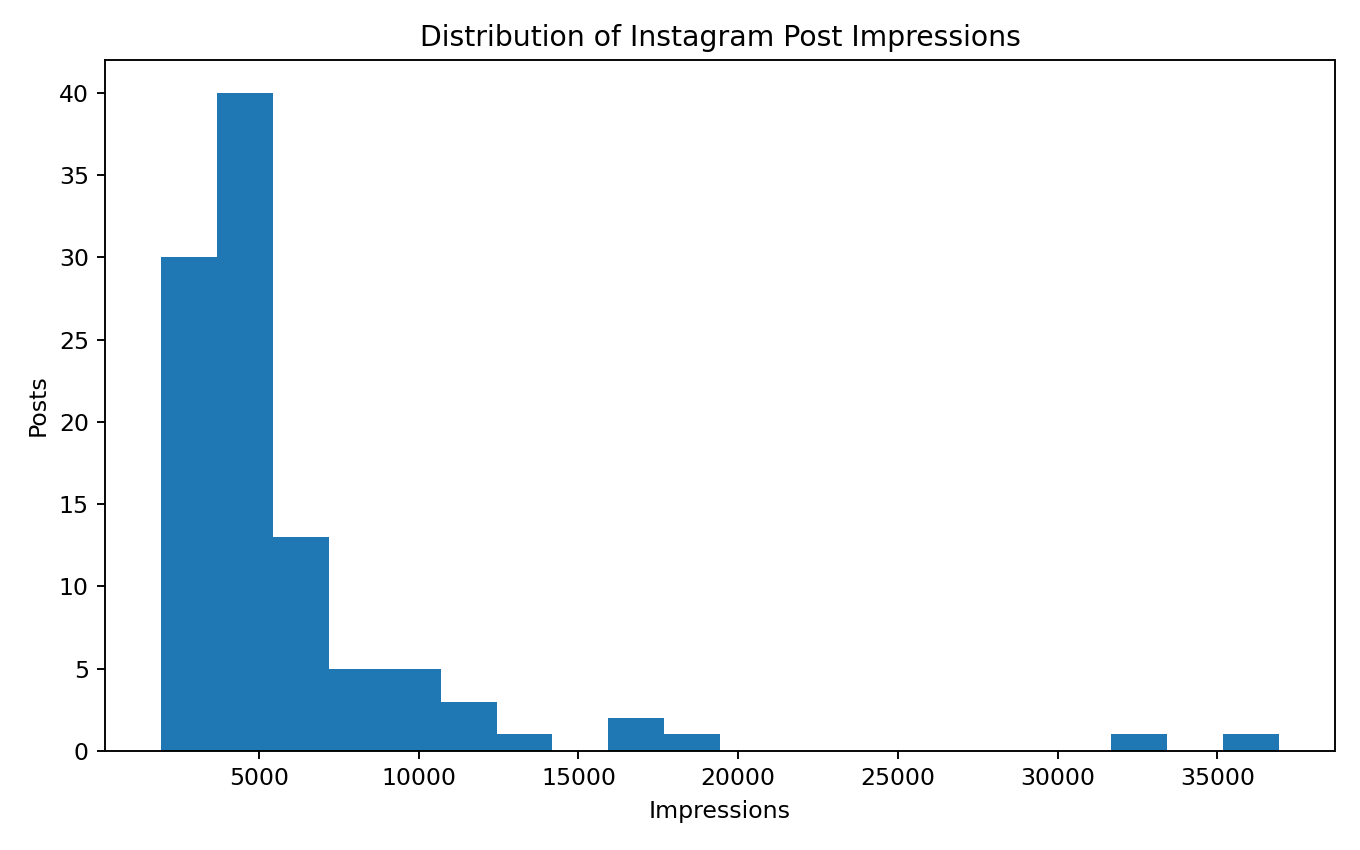

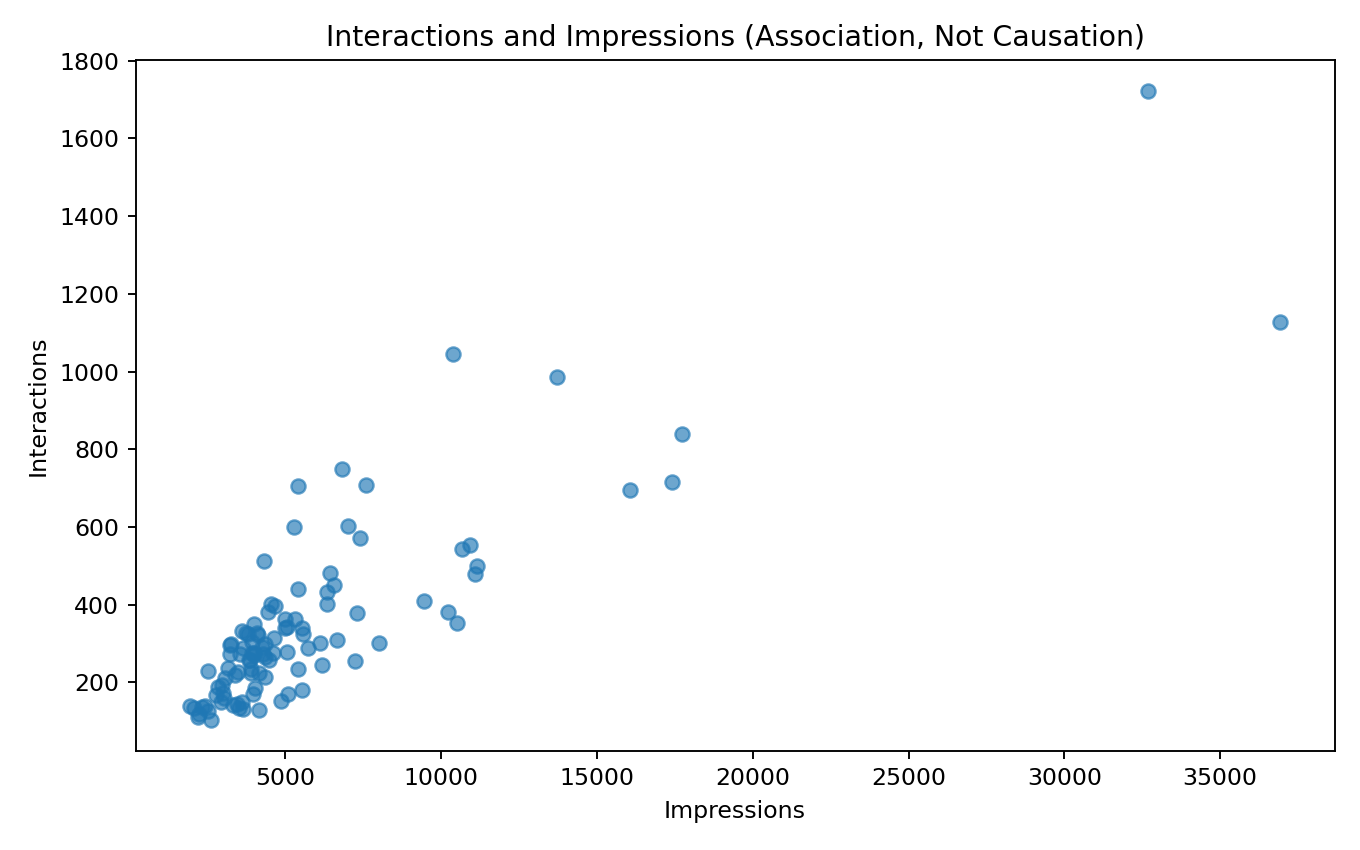

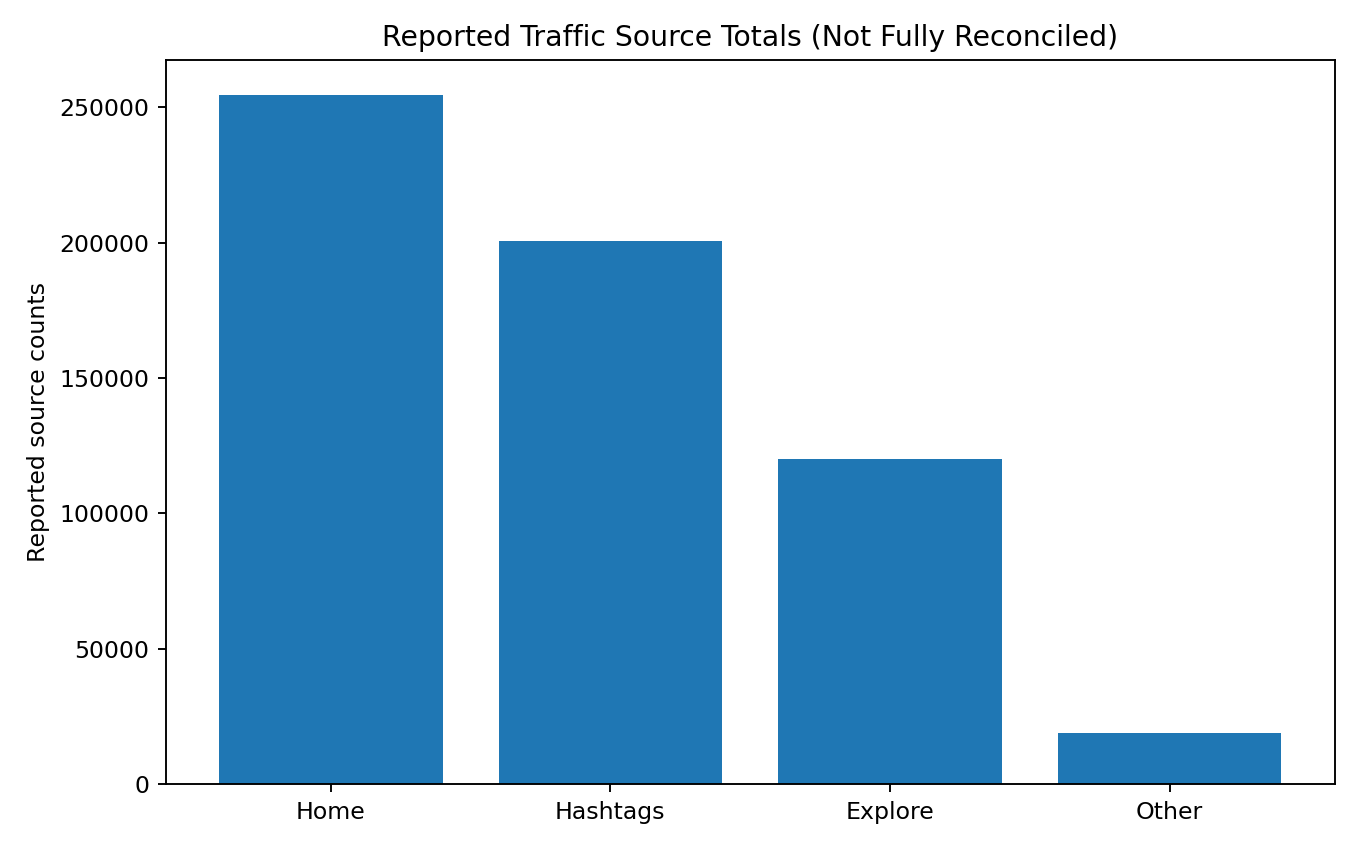

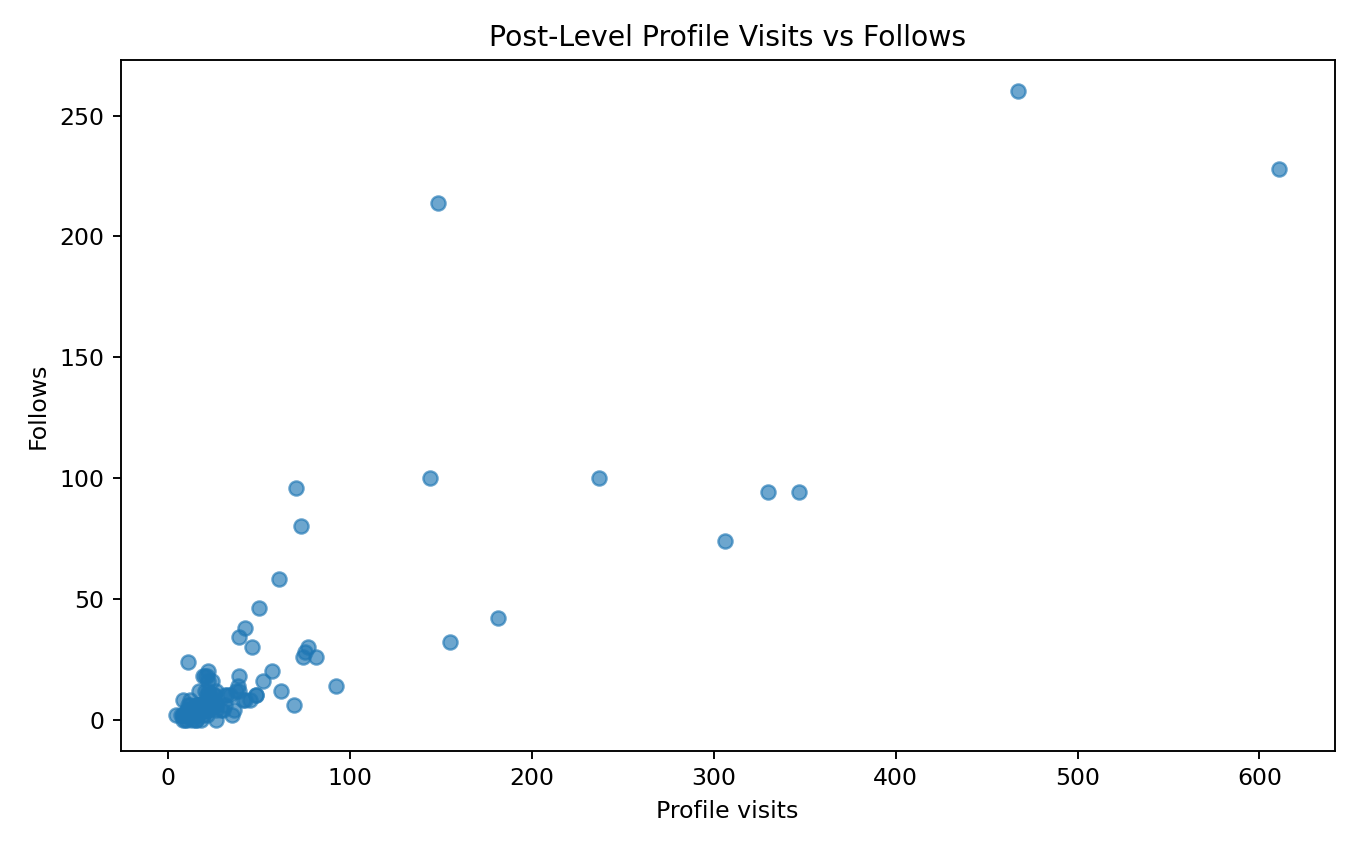

In [6]:
from IPython.display import Image, display
for name in ['impressions_distribution','interactions_vs_impressions','traffic_sources','visits_vs_follows']:
    display(Image(filename=str(ROOT/'outputs/figures'/f'{name}.png')))

## 4. Rank correlations (not causality)
Check relationships, outliers, and measurement limitations.

In [7]:
cor = pd.read_csv(ROOT/'outputs/spearman_correlations.csv',index_col=0)
display(cor[['impressions','profile_visits','follows']].round(2))
print('Impressions vs likes:',results['spearman_impressions_likes'])

,impressions,profile_visits,follows
impressions,1.00,0.66,0.77
likes,0.85,0.49,0.57
comments,0.28,0.10,-0.01
shares,0.48,0.13,0.25
saves,0.68,0.26,0.44
profile_visits,0.66,1.00,0.76
follows,0.77,0.76,1.00
caption_word_count,0.04,0.11,0.01
hashtag_count,-0.45,-0.42,-0.49
from_home,0.55,0.25,0.36


Impressions vs likes: 0.855


## 5. Sensitivity check: raw data vs exact-deduplicated data
Removing exact duplicates is an assumption because the CSV has no unique post IDs.

In [8]:
for label,d in [('Raw 119',raw),('Deduplicated 102',posts)]:
    impressions=d['Impressions'].sum() if label.startswith('Raw') else d['impressions'].sum()
    interactions=(d[['Likes','Comments','Shares','Saves']].sum().sum() if label.startswith('Raw') else d['interactions'].sum())
    follows=d['Follows'].sum() if label.startswith('Raw') else d['follows'].sum()
    print(label,': engagement/impressions =',round(interactions/impressions*100,2),'%; follows/impressions =',round(follows/impressions*100,2),'%')

Raw 119 : engagement/impressions = 6.02 %; follows/impressions = 0.36 %
Deduplicated 102 : engagement/impressions = 5.9 %; follows/impressions = 0.39 %


## Conclusions to present
Discuss which metrics correlate and how strongly (not why algorithmically); note small sample, missing dates/IDs and traffic reconciliation issues. See README and methodology for scope.